# Часть I: Исследование одной характеристики

**Гипотезы**  
- $H_0$: $Exp(λ); λ₀ = 2 / sqrt(3))$  
- $H_1$: $Pareto(α); α₀ = 3$  

**Методы**  
1. **KNN-граф** c(G)-Число компонент связности  
2. **DIST-граф** X(G)-Хроматическое число  
3. **χ²-тест** по 10 равноправным бинам, уровень $\alpha=0.05$  


In [1]:
# 1) Настройка среды и импорты
import sys
sys.path.append('..')  # чтобы Python увидел папку src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import networkx as nx
from scipy.stats import norm, laplace, chisquare

from src.generators import sample_H2, sample_H3
from src.graphs import build_knn_graph, build_distance_graph
from src.features import count_connected_components, compute_chromatic_number

In [2]:
# 2) Параметры эксперимента
n      = 1000    # размер выборки
M      = 1000    # число симуляций
alpha  = 0.05    # уровень значимости
k_knn  = 3       # параметр k
d_dist = 0.6     # радиус d
beta0  = np.sqrt(0.5)  # Laplace scale

In [3]:
# 3) Monte-Carlo: генерируем M выборок для H2 и H3
h0_samples = [sample_H2(n) for _ in tqdm(range(M), desc='Gen H2')]
h1_samples = [sample_H3(n) for _ in tqdm(range(M), desc='Gen H3')]

Gen H3: 100%|████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 6354.13it/s]


In [4]:
# 4a) KNN-граф: Число компонент связности
tri0 = [count_connected_components(build_knn_graph(x, k_knn)) for x in tqdm(h0_samples, desc='KNN H2')]
tri1 = [count_connected_components(build_knn_graph(x, k_knn)) for x in tqdm(h1_samples, desc='KNN H3')]



KNN H3: 100%|██████████████████████████████████████████████████████████████████████| 1000/1000 [00:13<00:00, 73.13it/s]


In [5]:
def chromatic_number(graph) -> int:
    """
    Находит хроматическое число графа с помощью жадного алгоритма раскраски.
    
    Параметры:
    ----------
    graph : nx.Graph
        Граф, для которого нужно найти хроматическое число.
        
    Возвращает:
    -----------
    int
        Хроматическое число графа.
    """
    # Получаем раскраску графа с помощью жадного алгоритма
    coloring = nx.coloring.greedy_color(graph, strategy="random_sequential")
    
    # Находим количество использованных цветов (хроматическое число при жадной раскраске)
    chromatic_num = max(coloring.values()) + 1  # +1 т.к. цвета нумеруются с 0
    
    return chromatic_num

In [6]:
# 4b) DIST-граф: Хроматическое число
h5_samples = [sample_H2(n) for _ in tqdm(range(100), desc='Gen H2')]
h6_samples = [sample_H3(n) for _ in tqdm(range(100), desc='Gen H3')]

clique0 = [
    chromatic_number(build_distance_graph(x,d_dist))
    for x in tqdm(h5_samples, desc='Chrom H2')
]
clique1 = [
    chromatic_number(build_distance_graph(x,d_dist))
    for x in tqdm(h6_samples, desc='Chrom H3')
]

Chrom H3: 100%|██████████████████████████████████████████████████████████████████████| 100/100 [00:41<00:00,  2.42it/s]


In [7]:
# 5) χ²-тест по 10 equiprobable бинам, рассчитанным от H0
num_bins  = 10
probs     = np.linspace(0, 1, num_bins+1)
bin_edges = norm.ppf(probs, loc=0, scale=1)

def stat_chi2(x):
    obs, _ = np.histogram(x, bins=bin_edges)
    exp    = np.full(num_bins, len(x)/num_bins)
    return chisquare(f_obs=obs, f_exp=exp)

p0 = [stat_chi2(x)[1] for x in tqdm(h0_samples, desc='Chi2 H0')]
p1 = [stat_chi2(x)[1] for x in tqdm(h1_samples, desc='Chi2 H1')]

type1_chi2 = np.mean(np.array(p0) < alpha)
power_chi2 = np.mean(np.array(p1) < alpha)

Chi2 H1: 100%|███████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1330.17it/s]


1
1
2
3
5
7
10
Sweep KNN (t):


,k,power
0,1,0.036
1,2,0.053
2,3,0.039
3,5,0.031
4,7,0.019
5,10,0.007



Sweep DIST (ω):


,d,power
0,0.2,0.0
1,0.4,0.0
2,0.6,0.0
3,0.8,0.0
4,1.0,0.0


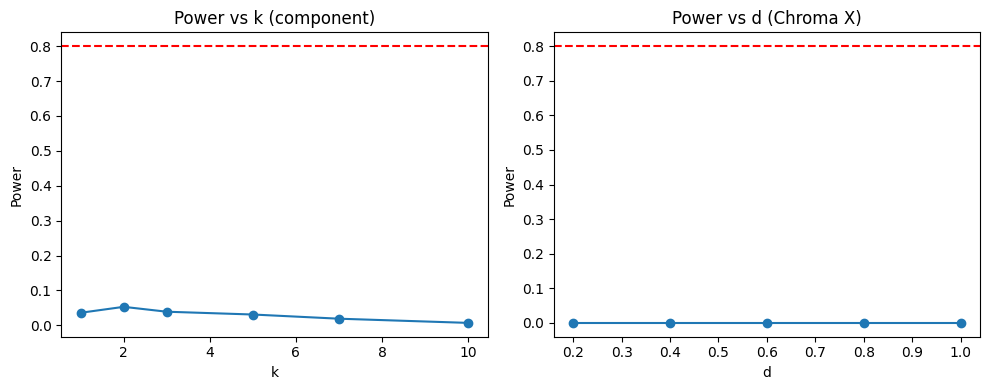

In [8]:
# === 5.5) Sweep-поиск по k и d ===
print(1)
# диапазоны параметров
ks = [1,2,3,5,7,10]
ds = [0.2,0.4,0.6,0.8,1.0]

# функция, возвращающая мощность одного критерия
def estimate_power(vals0, vals1, alpha=0.05):
    crit = np.percentile(vals0, 100*(1-alpha))
    return np.mean(np.array(vals1) > crit)

# 5.5a) Sweep для KNN-графа (c(G))
results_knn = []
for k in ks:
    print(k)
    t0 = [count_connected_components(build_knn_graph(x, k)) for x in h0_samples]
    t1 = [count_connected_components(build_knn_graph(x, k)) for x in h1_samples]
    beta = estimate_power(t0, t1, alpha)
    results_knn.append({'k': k, 'power': beta})
    
# 5.5b) Sweep для DIST-графа (X(G))
from src.features import compute_clique_number_1d
results_dist = []
for d in ds:
    c0 = [chromatic_number(build_distance_graph(x,d_dist)) for x in h5_samples]
    c1 = [chromatic_number(build_distance_graph(x,d_dist) )for x in h6_samples]
    beta = estimate_power(c0, c1, alpha)
    results_dist.append({'d': d, 'power': beta})

# Оборачиваем в DataFrame и отображаем
df_knn = pd.DataFrame(results_knn)
df_dist = pd.DataFrame(results_dist)

print("Sweep KNN (t):")
display(df_knn)
print("\nSweep DIST (ω):")
display(df_dist)

# И — для наглядности — пара графиков
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(df_knn['k'], df_knn['power'], marker='o')
plt.axhline(0.8, color='r', linestyle='--')
plt.title('Power vs k (component)')
plt.xlabel('k'); plt.ylabel('Power')

plt.subplot(1,2,2)
plt.plot(df_dist['d'], df_dist['power'], marker='o')
plt.axhline(0.8, color='r', linestyle='--')
plt.title('Power vs d (Chroma X)')
plt.xlabel('d'); plt.ylabel('Power')

plt.tight_layout()
plt.show()


In [9]:
# 6) Оценка критических порогов и мощностей

crit_tri  = np.percentile(tri0, 100*(1-alpha))
power_tri = np.mean(np.array(tri1) > crit_tri)

crit_cl   = np.percentile(clique0, 100*(1-alpha))
power_cl  = np.mean(np.array(clique1) > crit_cl)

print(f"KNN (component):   crit={crit_tri:.1f}, power={power_tri:.3f}")
print(f"DIST (Chroma x):   crit={crit_cl:.1f}, power={power_cl:.3f}")
print(f"χ²-test:           level I≈{type1_chi2:.3f}, power={power_chi2:.3f}")

KNN (component):   crit=63.0, power=0.039
DIST (Chroma x):   crit=439.1, power=0.000
χ²-test:           level I≈1.000, power=1.000


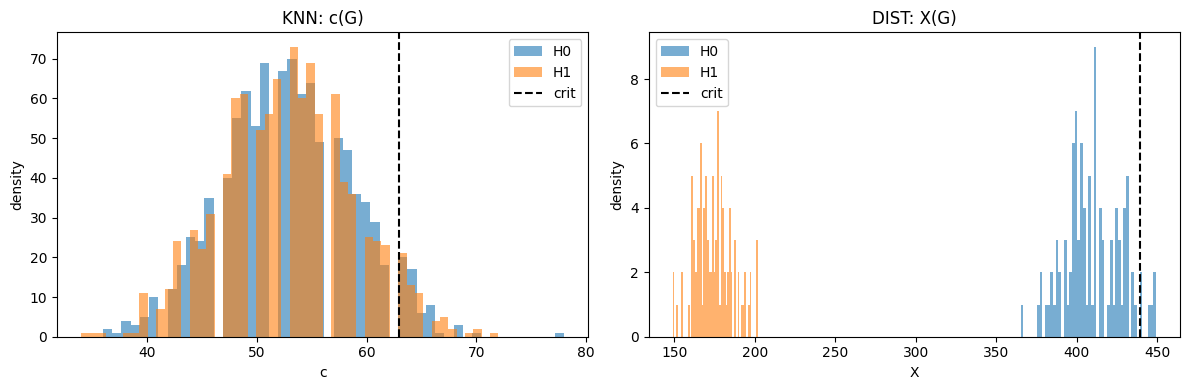

In [10]:
# 7a) Гистограммы самих статистик
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].hist(tri0, bins=50, alpha=0.6, label='H0')
ax[0].hist(tri1, bins=50, alpha=0.6, label='H1')
ax[0].axvline(crit_tri, color='k', linestyle='--', label='crit')
ax[0].set(title='KNN: c(G)', xlabel='c', ylabel='density')
ax[0].legend()

ax[1].hist(clique0, bins=50, alpha=0.6, label='H0')
ax[1].hist(clique1, bins=50, alpha=0.6, label='H1')
ax[1].axvline(crit_cl, color='k', linestyle='--', label='crit')
ax[1].set(title='DIST: X(G)', xlabel='X', ylabel='density')
ax[1].legend()

plt.tight_layout()
plt.show()

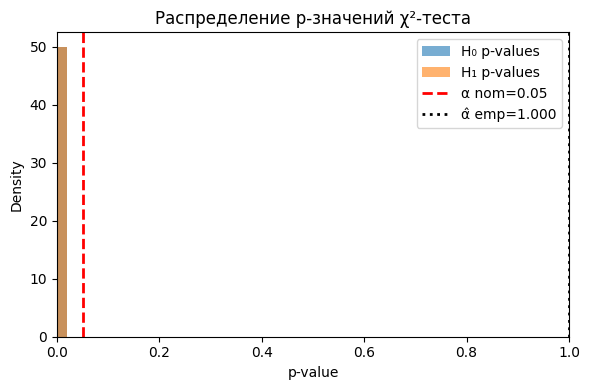

In [11]:
# 7b) Гистограмма p-значений χ²
plt.figure(figsize=(6,4))
plt.hist(p0, bins=50, range=(0,1), density=True, alpha=0.6, label='H₀ p-values')
plt.hist(p1, bins=50, range=(0,1), density=True, alpha=0.6, label='H₁ p-values')
plt.axvline(alpha,      color='r', linestyle='--', linewidth=2, label=f'α nom={alpha:.2f}')
plt.axvline(type1_chi2, color='k', linestyle=':',  linewidth=2, label=f'α̂ emp={type1_chi2:.3f}')
plt.xlim(0,1)
plt.xlabel('p-value')
plt.ylabel('Density')
plt.title('Распределение p-значений χ²-теста')
plt.legend()
plt.tight_layout()
plt.show()

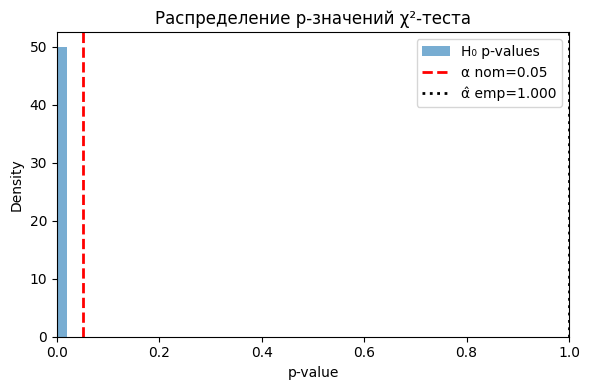

In [12]:
# 7b) Гистограмма p-значений χ²
plt.figure(figsize=(6,4))
plt.hist(p0, bins=50, range=(0,1), density=True, alpha=0.6, label='H₀ p-values')
plt.axvline(alpha,      color='r', linestyle='--', linewidth=2, label=f'α nom={alpha:.2f}')
plt.axvline(type1_chi2, color='k', linestyle=':',  linewidth=2, label=f'α̂ emp={type1_chi2:.3f}')
plt.xlim(0,1)
plt.xlabel('p-value')
plt.ylabel('Density')
plt.title('Распределение p-значений χ²-теста')
plt.legend()
plt.tight_layout()
plt.show()

**Выводы**

**KNN-граф (число компонент связности \$с(G)\$)**
   
*c(g) не очень хорошо разделяет exp от pareto*и

**DIST-граф (хроматического число \$X(G)\$)**

*X(G) - хроматическое число это хороший разделяющий признак*

*exp: хроматическое число небольшое (2-3), так как соседи находятся в узком диапазоне.*
*pareto: из-за тяжёлых хвостов появляются "далёкие" связи  требуются новые цвета*
$.

